In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime

import modules.dataloader as dl
import modules.timeseries as ts

In [2]:
marathias_ts = pd.read_csv('results/fault_ts_dfs/Marathias.csv', index_col=0, parse_dates=True)
marathias_ts

,left_mean_ts,left_uncertainty,right_mean_ts,right_uncertainty
2019-01-07,-0.222995,0.070818,-0.312055,0.095831
2019-01-13,-0.145789,0.069554,-0.080651,0.076262
2019-01-19,0.490107,0.064890,0.815672,0.076040
2019-01-25,0.287834,0.070687,0.656239,0.077325
2019-01-31,-0.506417,0.060343,-0.232369,0.064536
...,...,...,...,...
2023-11-30,-24.999866,0.326236,-15.645992,0.293743
2023-12-06,-25.196390,0.328466,-15.847740,0.292090
2023-12-12,-24.605949,0.319958,-15.183605,0.289048
2023-12-18,-24.483890,0.318239,-15.037914,0.288750


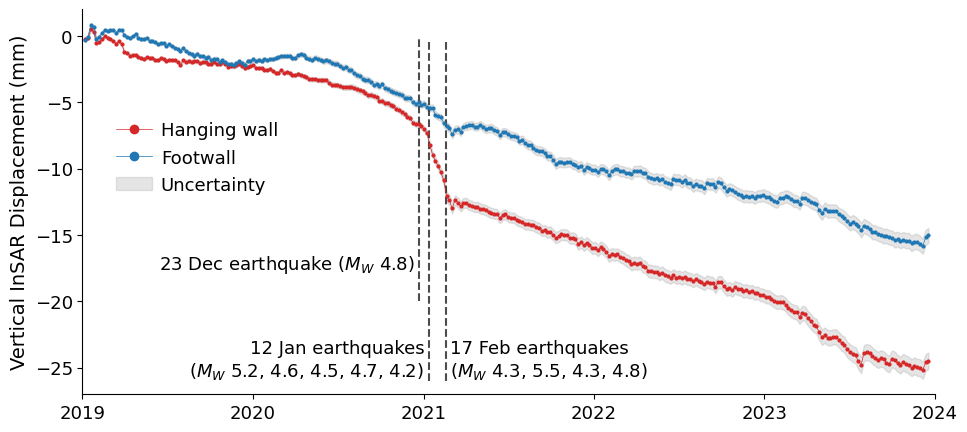

In [3]:
fig,ax = plt.subplots(figsize=(11,5))

ax.vlines(x=datetime.datetime(2020, 12, 23), ymin=-20, ymax=0, color='k', linewidth=1.5, linestyle='--', alpha=0.7)
ax.vlines(x=datetime.datetime(2021, 1, 12), ymin=-26, ymax=-0.5, color='k', linewidth=1.5, linestyle='--', alpha=0.7)
ax.vlines(x=datetime.datetime(2021, 2, 17), ymin=-26, ymax=-0.5, color='k', linewidth=1.5, linestyle='--', alpha=0.7)

ax.plot(marathias_ts['left_mean_ts'], '-o', color='tab:red', linewidth=0.5, markersize=2, label='Hanging wall')
ax.fill_between(marathias_ts.index, marathias_ts['left_mean_ts'] - 1.96 * marathias_ts['left_uncertainty'], \
                marathias_ts['left_mean_ts'] + 1.96 * marathias_ts['left_uncertainty'], color='grey', alpha=0.2)

ax.plot(marathias_ts['right_mean_ts'], '-o', color='tab:blue', linewidth=0.5, markersize=2, label='Footwall')
ax.fill_between(marathias_ts.index, marathias_ts['right_mean_ts'] - 1.96 * marathias_ts['right_uncertainty'], \
                marathias_ts['right_mean_ts'] + 1.96 * marathias_ts['right_uncertainty'], color='grey', alpha=0.2, label = 'Uncertainty')

ax.legend(frameon=False, loc='upper left', fontsize=13, bbox_to_anchor=(0.02, 0.75), markerscale=3, handletextpad=0.5, labelspacing=0.5)

ax.set_xlim([datetime.datetime(2019, 1, 1), datetime.datetime(2024, 1, 1)])
ax.set_ylabel('Vertical InSAR Displacement (mm)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=13)
ax.set_ylim([-27, 2])

ax.text(datetime.datetime(2020, 12, 23)-datetime.timedelta(days=10), -18, '23 Dec earthquake ($M_W$ 4.8)', \
        fontsize=13, ha='right', va='bottom')
ax.text(datetime.datetime(2021, 1, 12)-datetime.timedelta(days=10), -26, '12 Jan earthquakes\n($M_W$ 5.2, 4.6, 4.5, 4.7, 4.2)', \
        fontsize=13, ha='right', va='bottom')
ax.text(datetime.datetime(2021, 2, 17)+datetime.timedelta(days=10), -26, '17 Feb earthquakes\n($M_W$ 4.3, 5.5, 4.3, 4.8)', \
        fontsize=13, ha='left', va='bottom')


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig('figures/Marathias_timeseries.png', dpi=300, bbox_inches='tight', transparent=True,  edgecolor='k')

In [4]:
marathias_eq_df = marathias_ts.loc[datetime.datetime(2020, 12, 9)-datetime.timedelta(days=6):\
                                   datetime.datetime(2021, 3, 3)+datetime.timedelta(days=6)]

marathias_eq_df

,left_mean_ts,left_uncertainty,right_mean_ts,right_uncertainty
2020-12-03,-6.203610,0.106176,-4.709464,0.119679
2020-12-09,-6.529947,0.104148,-5.012477,0.121536
2020-12-15,-6.648061,0.104372,-5.134840,0.117468
2020-12-21,-6.627273,0.104360,-4.996323,0.120178
2020-12-27,-6.816778,0.107504,-5.183725,0.122934
2021-01-02,-7.025267,0.106718,-5.120615,0.126786
2021-01-08,-7.325936,0.104669,-5.376130,0.124401
2021-01-14,-8.224198,0.117067,-5.432188,0.124661
2021-01-20,-8.942580,0.121582,-5.415431,0.132675
2021-01-26,-9.400000,0.135397,-5.943400,0.132512


In [5]:
left_diff = marathias_eq_df.iloc[0].left_mean_ts - marathias_eq_df.iloc[-1].left_mean_ts
left_diff_uncertainty = np.sqrt(marathias_eq_df.iloc[0].left_uncertainty**2 + marathias_eq_df.iloc[-1].left_uncertainty**2)
print(f"Left mean displacement difference: {left_diff:.2f} ± {left_diff_uncertainty:.2f} mm")

Left mean displacement difference: 6.19 ± 0.22 mm


In [6]:
right_diff = marathias_eq_df.iloc[0].right_mean_ts - marathias_eq_df.iloc[-1].right_mean_ts
right_diff_uncertainty = np.sqrt(marathias_eq_df.iloc[0].right_uncertainty**2 + marathias_eq_df.iloc[-1].right_uncertainty**2)
print(f"Right mean displacement difference: {right_diff:.2f} ± {right_diff_uncertainty:.2f} mm")

Right mean displacement difference: 2.36 ± 0.20 mm


In [7]:
time_diff = marathias_eq_df.index[-1] - marathias_eq_df.index[0]
print(f"Time difference between first and last measurement: {time_diff.days} days")

Time difference between first and last measurement: 96 days


In [8]:
rion_patras_ts = pd.read_csv('results/fault_ts_dfs/Rion-Patras.csv', index_col=0, parse_dates=True)

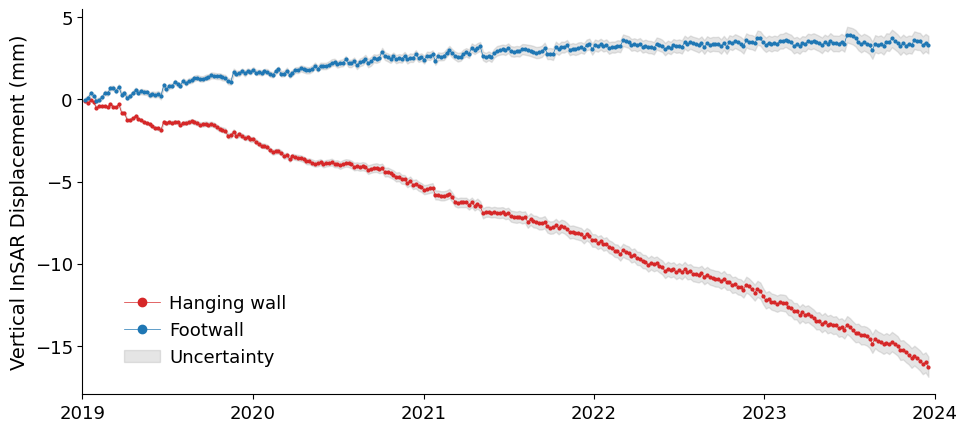

In [9]:
fig,ax = plt.subplots(figsize=(11,5))

ax.plot(rion_patras_ts['left_mean_ts'], '-o', color='tab:red', linewidth=0.5, markersize=2, label='Hanging wall')
ax.fill_between(rion_patras_ts.index, rion_patras_ts['left_mean_ts'] - 1.96 * rion_patras_ts['left_uncertainty'], \
                rion_patras_ts['left_mean_ts'] + 1.96 * rion_patras_ts['left_uncertainty'], color='grey', alpha=0.2)

ax.plot(rion_patras_ts['right_mean_ts'], '-o', color='tab:blue', linewidth=0.5, markersize=2, label='Footwall')
ax.fill_between(rion_patras_ts.index, rion_patras_ts['right_mean_ts'] - 1.96 * rion_patras_ts['right_uncertainty'], \
                rion_patras_ts['right_mean_ts'] + 1.96 * rion_patras_ts['right_uncertainty'], color='grey', alpha=0.2, label = 'Uncertainty')

ax.legend(frameon=False, loc='lower left', fontsize=13, bbox_to_anchor=(0.03, 0.03), markerscale=3, handletextpad=0.5, labelspacing=0.5)

ax.set_xlim([datetime.datetime(2019, 1, 1), datetime.datetime(2024, 1, 1)])
ax.set_ylabel('Vertical InSAR Displacement (mm)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig('figures/Rion-Patras_timeseries.png', dpi=300, bbox_inches='tight', transparent=True,  edgecolor='k')

In [10]:
atalanti_ts = pd.read_csv('results/fault_ts_dfs/Atalanti.csv', index_col=0, parse_dates=True)
left_trend, _, _ = ts.stl_decomposition(atalanti_ts['left_mean_ts'][:-1])
right_trend, _, _ = ts.stl_decomposition(atalanti_ts['right_mean_ts'][:-1])

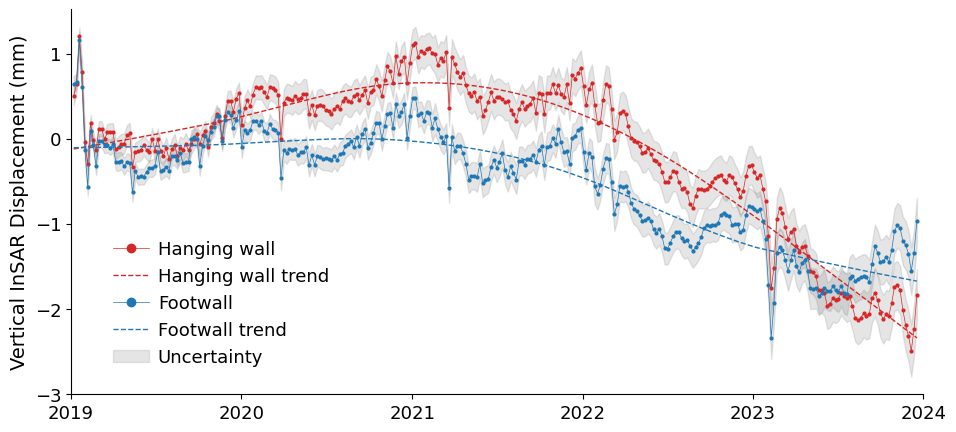

In [11]:
fig,ax = plt.subplots(figsize=(11,5))

ax.plot(atalanti_ts['left_mean_ts'], '-o', color='tab:red', linewidth=0.5, markersize=2, label='Hanging wall')
ax.fill_between(atalanti_ts.index, atalanti_ts['left_mean_ts'] - 1.96 * atalanti_ts['left_uncertainty'], \
                atalanti_ts['left_mean_ts'] + 1.96 * atalanti_ts['left_uncertainty'], color='grey', alpha=0.2)
ax.plot(left_trend, '--', color='tab:red', linewidth=1, label='Hanging wall trend')

ax.plot(atalanti_ts['right_mean_ts'], '-o', color='tab:blue', linewidth=0.5, markersize=2, label='Footwall')
ax.plot(right_trend, '--', color='tab:blue', linewidth=1, label='Footwall trend')
ax.fill_between(atalanti_ts.index, atalanti_ts['right_mean_ts'] - 1.96 * atalanti_ts['right_uncertainty'], \
                atalanti_ts['right_mean_ts'] + 1.96 * atalanti_ts['right_uncertainty'], color='grey', alpha=0.2, label = 'Uncertainty')

ax.set_xlim([datetime.datetime(2019, 1, 1), datetime.datetime(2024, 1, 1)])
ax.set_ylabel('Vertical InSAR Displacement (mm)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False, loc='lower left', fontsize=13, bbox_to_anchor=(0.03, 0.03), markerscale=3, handletextpad=0.5, labelspacing=0.5)

plt.savefig('figures/Atalanti_timeseries.png', dpi=300, bbox_inches='tight', transparent=True,  edgecolor='k')

In [12]:
kalavrita_ts = pd.read_csv('results/fault_ts_dfs/Kalavrita.csv', index_col=0, parse_dates=True)

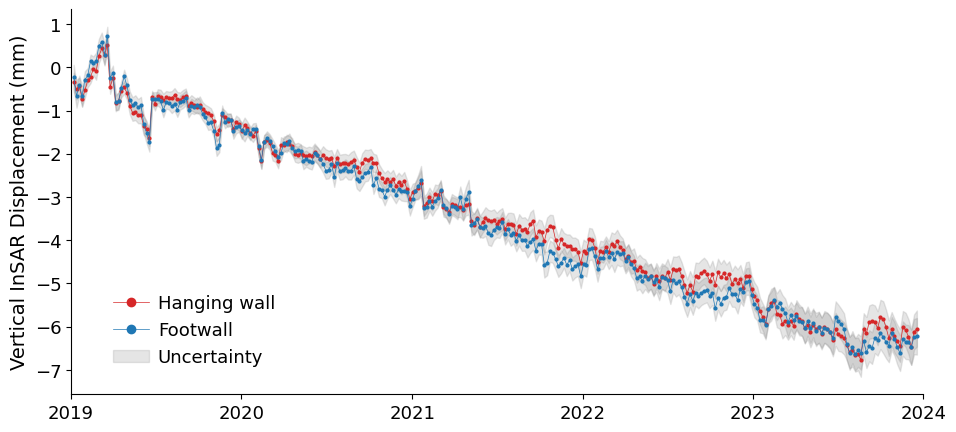

In [13]:
fig,ax = plt.subplots(figsize=(11,5))

ax.plot(kalavrita_ts['left_mean_ts'], '-o', color='tab:red', linewidth=0.5, markersize=2, label='Hanging wall')
ax.fill_between(kalavrita_ts.index, kalavrita_ts['left_mean_ts'] - 1.96 * kalavrita_ts['left_uncertainty'], \
                kalavrita_ts['left_mean_ts'] + 1.96 * kalavrita_ts['left_uncertainty'], color='grey', alpha=0.2)

ax.plot(kalavrita_ts['right_mean_ts'], '-o', color='tab:blue', linewidth=0.5, markersize=2, label='Footwall')
ax.fill_between(kalavrita_ts.index, kalavrita_ts['right_mean_ts'] - 1.96 * kalavrita_ts['right_uncertainty'], \
                kalavrita_ts['right_mean_ts'] + 1.96 * kalavrita_ts['right_uncertainty'], color='grey', alpha=0.2, label = 'Uncertainty')

ax.set_xlim([datetime.datetime(2019, 1, 1), datetime.datetime(2024, 1, 1)])
ax.set_ylabel('Vertical InSAR Displacement (mm)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False, loc='lower left', fontsize=13, bbox_to_anchor=(0.03, 0.03), markerscale=3, handletextpad=0.5, labelspacing=0.5)

plt.savefig('figures/Kalavrita_timeseries.png', dpi=300, bbox_inches='tight', transparent=True,  edgecolor='k')

In [15]:
skinos_ts = pd.read_csv('results/fault_ts_dfs/Skinos-Psatha.csv', index_col=0, parse_dates=True)

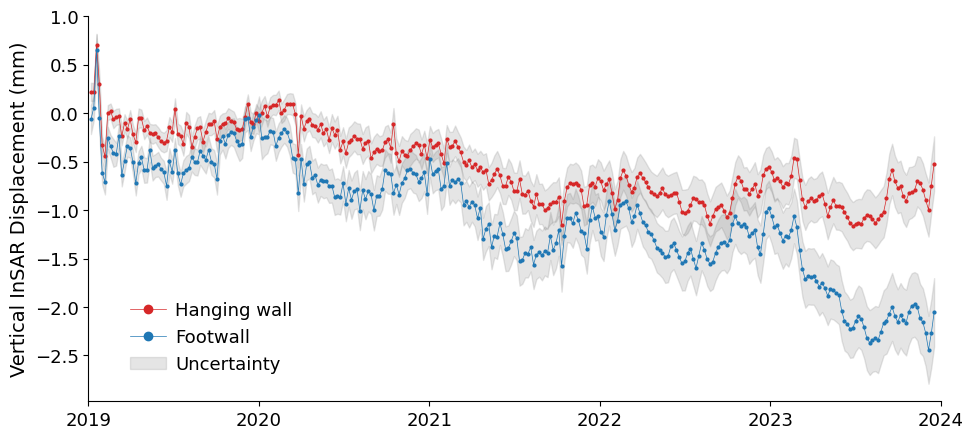

In [16]:
fig,ax = plt.subplots(figsize=(11,5))

ax.plot(skinos_ts['left_mean_ts'], '-o', color='tab:red', linewidth=0.5, markersize=2, label='Hanging wall')
ax.fill_between(skinos_ts.index, skinos_ts['left_mean_ts'] - 1.96 * skinos_ts['left_uncertainty'], \
                skinos_ts['left_mean_ts'] + 1.96 * skinos_ts['left_uncertainty'], color='grey', alpha=0.2)

ax.plot(skinos_ts['right_mean_ts'], '-o', color='tab:blue', linewidth=0.5, markersize=2, label='Footwall')
ax.fill_between(skinos_ts.index, skinos_ts['right_mean_ts'] - 1.96 * skinos_ts['right_uncertainty'], \
                skinos_ts['right_mean_ts'] + 1.96 * skinos_ts['right_uncertainty'], color='grey', alpha=0.2, label = 'Uncertainty')

ax.set_xlim([datetime.datetime(2019, 1, 1), datetime.datetime(2024, 1, 1)])
ax.set_ylabel('Vertical InSAR Displacement (mm)', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False, loc='lower left', fontsize=13, bbox_to_anchor=(0.03, 0.03), markerscale=3, handletextpad=0.5, labelspacing=0.5)

plt.savefig('figures/Skinos_timeseries.png', dpi=300, bbox_inches='tight', transparent=True,  edgecolor='k')